In [6]:
import pandas as pd

df_train = pd.read_csv("training_set.csv")
df_valid = pd.read_csv("validation_set.csv")
df_test = pd.read_csv("test_set.csv")

df_train.head()

,SampleID,feature1,feature2,feature3,feature4,feature5,label
0,TRAIN_001,0.599758,0.012166,0.209270,1.087926,4.088241,0
1,TRAIN_002,-5.512324,-0.426576,-0.092336,0.501431,3.844389,0
2,TRAIN_003,-3.387749,2.786477,0.195597,1.540859,4.148680,0
3,TRAIN_004,-4.690195,-1.024081,-0.101571,0.981619,3.712296,0
4,TRAIN_005,7.990252,0.398343,-0.302286,1.309536,3.870292,0


In [7]:
features = ['feature1', 'feature2', 'feature3', 'feature4', 'feature5']
X = df_train[features]
y = df_train["label"]
X_valid = df_valid[features]
X_final = df_test[features]

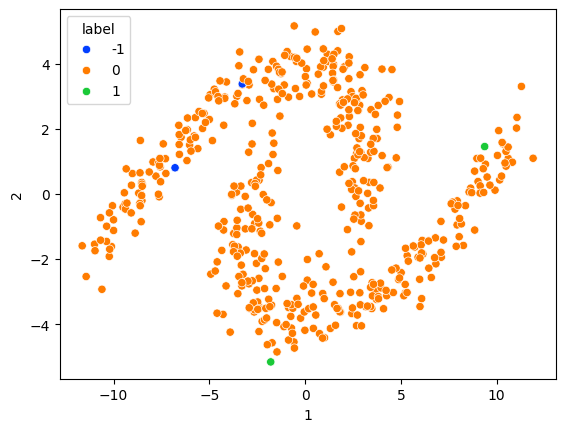

In [9]:
#ne uitam putin sa vedem clusteruri
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X = pd.DataFrame(pca.fit_transform(X), columns=['1', '2'])
X_valid = pd.DataFrame(pca.transform(X_valid), columns=['1', '2'])
X_final = pd.DataFrame(pca.transform(X_final), columns=['1', '2'])

#se vad doua clusterurui foarte clare in forma de simbol nike gen
sns.scatterplot(x=X['1'], y=X['2'], hue=y, palette='bright')
plt.show()

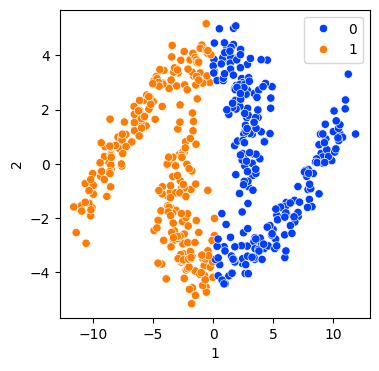

In [15]:
from sklearn.cluster import KMeans # ts is shit n are nicio treaba

kmeans = KMeans(n_clusters=2)

labels = kmeans.fit_predict(X)

plt.figure(figsize=(4, 4))
sns.scatterplot(x=X['1'], y=X['2'], hue=labels, palette='bright')
plt.show()

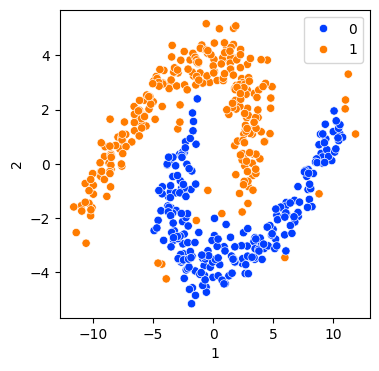

In [14]:
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.7, min_samples=4)

labels = db.fit_predict(X)
labels = [abs(label) for label in labels]
y = labels

plt.figure(figsize=(4, 4))
sns.scatterplot(x=X['1'], y=X['2'], hue=y, palette='bright')
plt.show()

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

model = RandomForestClassifier(random_state=42)

cross_val_score(model, X, y, cv=5, scoring='accuracy')

array([0.99, 0.98, 0.98, 0.94, 0.97])

In [18]:
model.fit(X, y)
y_1 = model.predict(X_valid)
y_2 = model.predict(X_final)

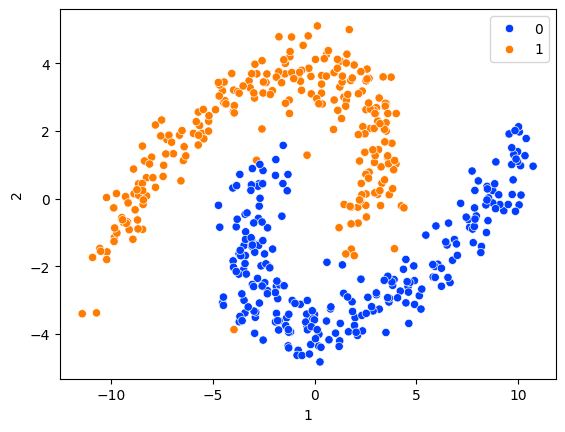

In [19]:
sns.scatterplot(x=X_valid['1'], y=X_valid['2'], hue=y_1, palette='bright')
plt.show()

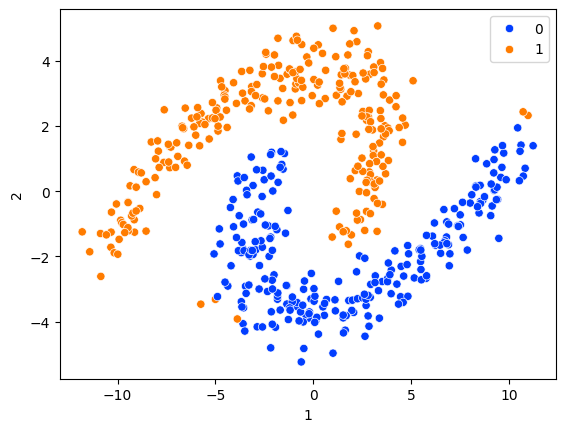

In [21]:
sns.scatterplot(x=X_final['1'], y=X_final['2'], hue=y_2, palette='bright')
plt.show()

In [25]:
y_1 = pd.Series(y_1).map({0: 1, 1: -1})
y_2 = pd.Series(y_2).map({0: 1, 1: -1})

In [26]:
df_1 = pd.DataFrame({
    "SampleID": df_valid.SampleID,
    "ClasamentType": 'A',
    "label": y_1
})

df_2 = pd.DataFrame({
    "SampleID": df_test.SampleID,
    "ClasamentType": 'B',
    "label": y_2
})

submission = pd.concat([df_1, df_2])
submission

,SampleID,ClasamentType,label
0,VALIDATION_001,A,1
1,VALIDATION_002,A,1
2,VALIDATION_003,A,1
3,VALIDATION_004,A,-1
4,VALIDATION_005,A,1
...,...,...,...
495,TEST_496,B,1
496,TEST_497,B,1
497,TEST_498,B,-1
498,TEST_499,B,-1


In [27]:
submission.to_csv("submission.csv", index=False)

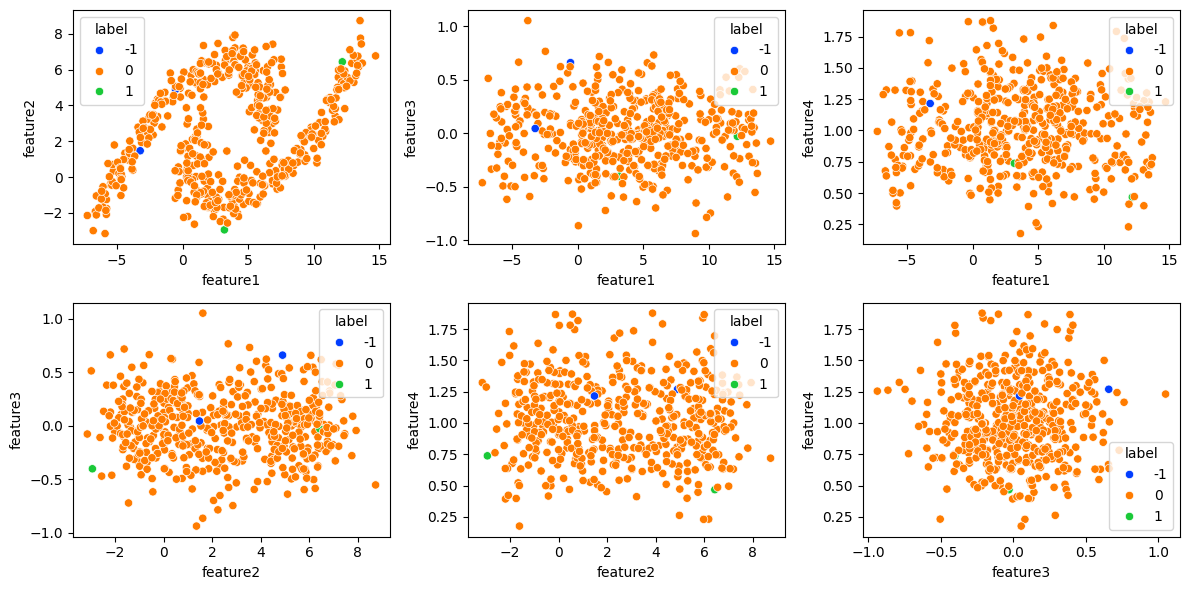

In [28]:
# BONUS featureurile 1 si 2 sunt alea bune deja decomposed gen

from itertools import combinations
fig, axes = plt.subplots(2, 3, figsize=(12, 6))

for ax, (x, y) in zip(axes.flat, combinations(["feature1","feature2","feature3","feature4"], 2)):
    sns.scatterplot(x=x, y=y, data=df_train, hue="label", ax=ax, palette='bright')

plt.tight_layout()
plt.show()